# code_103 · Shared features and task-specific output heads

**Book:** section 21.1. A self-contained neural-training laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_21_GUIDE.md), [run evidence](../CHAPTER_21_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_103).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2203;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2203


<a id="head-contract"></a>
 ## Inputs and outputs are different objects
 Generate 60 buildings × six members; 40/10/10 whole buildings supply training/development/final data. Two continuous inputs are standardized with training statistics. A categorical lookup represents three admitted member types plus missing and unknown tokens. Missing tokens have training support; a separate unknown-type probe is explicitly rejected. A shared twelve-unit ReLU torso feeds a Gaussian mean/positive-variance head, two independent Bernoulli logits and three exclusive-state logits. Fixed unit weights sum Gaussian NLL, binary logit loss and exclusive cross entropy. No final result selects loss weights or a model.


,MSE,Gaussian_NLL,binary_Brier,exclusive_cross_entropy,exclusive_accuracy
development,0.052621,0.092470,0.247067,1.112879,0.416667
final,0.049824,-0.003549,0.208112,1.153885,0.466667


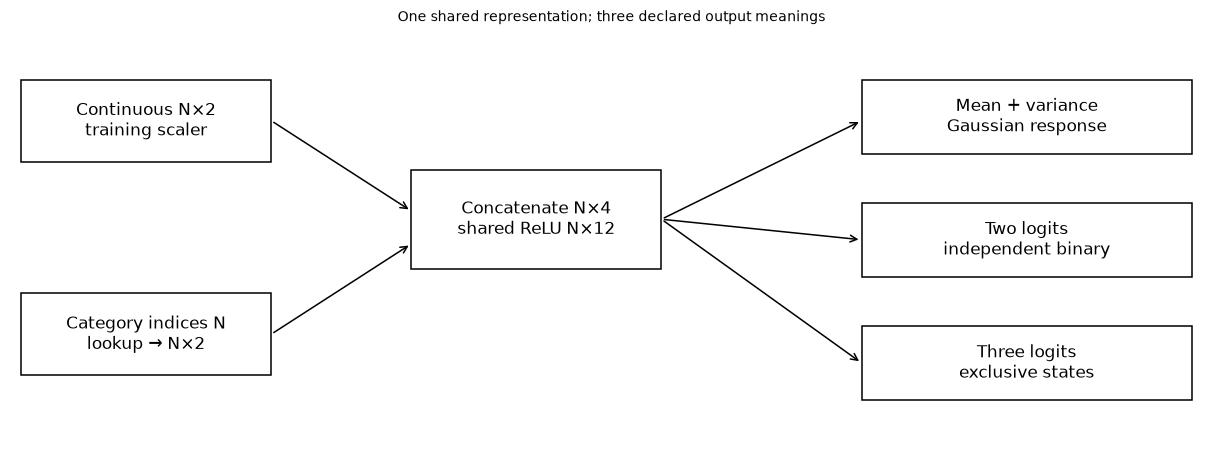

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import brier_score_loss,accuracy_score,confusion_matrix
from matplotlib.patches import Rectangle
building=np.repeat(np.arange(60),6);continuous=np.column_stack([rng.uniform(.2,2.,360),rng.normal(1.,.2,360)])
physical_type=rng.integers(0,3,360);category=physical_type.copy();category[rng.random(360)<.06]=3
load,slender=continuous.T;mu=1+.6*load+.4*slender+np.array([0.,.2,-.1])[physical_type];sigma=.08+.1*load;response=mu+rng.normal(0,sigma)
binary_probability=np.column_stack([1/(1+np.exp(-(-1+load-.6*slender+.3*physical_type))),1/(1+np.exp(-(slender-.5*load)))])
binary=rng.binomial(1,binary_probability).astype(float)
state_logits=np.column_stack([1-load,load-.7,slender-.8]);state=np.argmax(state_logits+rng.gumbel(size=(360,3)),axis=1)
train=building<40;dev=(building>=40)&(building<50);final=building>=50
scaler=StandardScaler().fit(continuous[train]);x=torch.tensor(scaler.transform(continuous));cat=torch.tensor(category,dtype=torch.long);y=torch.tensor(response);yb=torch.tensor(binary);ys=torch.tensor(state,dtype=torch.long)
assert set(building[train]).isdisjoint(building[final]) and len(np.unique(category[train]))==4
class MemberNetwork(nn.Module):
    def __init__(self):
        super().__init__();self.embedding=nn.Embedding(5,2);self.torso=nn.Sequential(nn.Linear(4,12),nn.ReLU());self.gaussian=nn.Linear(12,2);self.bernoulli=nn.Linear(12,2);self.states=nn.Linear(12,3)
    def forward(self,values,types):
        h=self.torso(torch.cat([values,self.embedding(types)],dim=1));normal=self.gaussian(h)
        return normal[:,0],nn.functional.softplus(normal[:,1])+1e-4,self.bernoulli(h),self.states(h)
model=MemberNetwork();optimizer=torch.optim.AdamW(model.parameters(),lr=.02,weight_decay=.001);normal_loss=nn.GaussianNLLLoss(full=True);binary_loss=nn.BCEWithLogitsLoss();state_loss=nn.CrossEntropyLoss();loss_history=[]
for step in range(500):
    optimizer.zero_grad();mean,var,logits,class_logits=model(x[train],cat[train]);parts=[normal_loss(mean,y[train],var),binary_loss(logits,yb[train]),state_loss(class_logits,ys[train])];loss=sum(parts);loss.backward();optimizer.step()
    if step%25==0:loss_history.append([step,*[float(v.detach()) for v in parts]])
model.eval()
def assess(mask):
    with torch.no_grad():
        mean,var,logits,class_logits=model(x[mask],cat[mask]);p=torch.sigmoid(logits);classes=torch.softmax(class_logits,dim=1)
        assert mean.shape==(int(mask.sum()),) and logits.shape==(int(mask.sum()),2) and classes.shape==(int(mask.sum()),3)
        assert torch.all(var>0);np.testing.assert_allclose(classes.sum(1).numpy(),1,atol=1e-12)
        return {'MSE':float(torch.mean((mean-y[mask])**2)),'Gaussian_NLL':float(normal_loss(mean,y[mask],var)),'binary_Brier':float(torch.mean((p-yb[mask])**2)),'exclusive_cross_entropy':float(state_loss(class_logits,ys[mask])),'exclusive_accuracy':float((class_logits.argmax(1)==ys[mask]).double().mean())},(mean.numpy(),var.numpy(),p.numpy(),classes.numpy())
development,dev_outputs=assess(dev);assessment,outputs=assess(final)
def admitted_forward(values,types):
    if torch.any(types==4):raise ValueError('Unknown member type has no validated embedding support')
    return model(values,types)
rejected=False
try:admitted_forward(x[:1],torch.tensor([4]))
except ValueError:rejected=True
assert rejected
RESULTS.update(development=development,final=assessment,split_buildings=[40,10,10],parameter_count=sum(p.numel() for p in model.parameters()),training_steps=500,unknown_type_rejected=rejected,head_shapes={'mean':[60],'variance':[60],'binary_logits':[60,2],'exclusive_logits':[60,3]},training_losses=loss_history)
display(pd.DataFrame([development,assessment],index=['development','final']))
fig,ax=plt.subplots(figsize=(11,4));ax.set(xlim=(0,12),ylim=(0,5));ax.axis('off')
boxes=[(.1,3.4,2.5,1.,'Continuous N×2\ntraining scaler'),(.1,.8,2.5,1.,'Category indices N\nlookup → N×2'),(4,2.1,2.5,1.2,'Concatenate N×4\nshared ReLU N×12'),(8.5,3.5,3.3,.9,'Mean + variance\nGaussian response'),(8.5,2.,3.3,.9,'Two logits\nindependent binary'),(8.5,.5,3.3,.9,'Three logits\nexclusive states')]
for a,b,w,h,label in boxes:ax.add_patch(Rectangle((a,b),w,h,fill=False));ax.text(a+w/2,b+h/2,label,ha='center',va='center')
for start,end in [((2.6,3.9),(4,2.8)),((2.6,1.3),(4,2.4)),((6.5,2.7),(8.5,3.9)),((6.5,2.7),(8.5,2.45)),((6.5,2.7),(8.5,.95))]:ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->'})
ax.set_title('One shared representation; three declared output meanings');plt.show()


<a id="loss-meaning"></a>
 ## Losses express the head contracts
 The Gaussian head supplies conditional mean and variance, not a confidence interval for a physical parameter. Bernoulli probabilities need not sum to one across outcomes; exclusive-state probabilities do. Unit loss weights are a declared multi-task choice, not a scale-neutral law. Shared parameters receive gradients from all three tasks. The untrained unknown embedding row exists technically but its output is not admitted as a validated prediction. The generated response/risk mechanism is not a structural assessment.


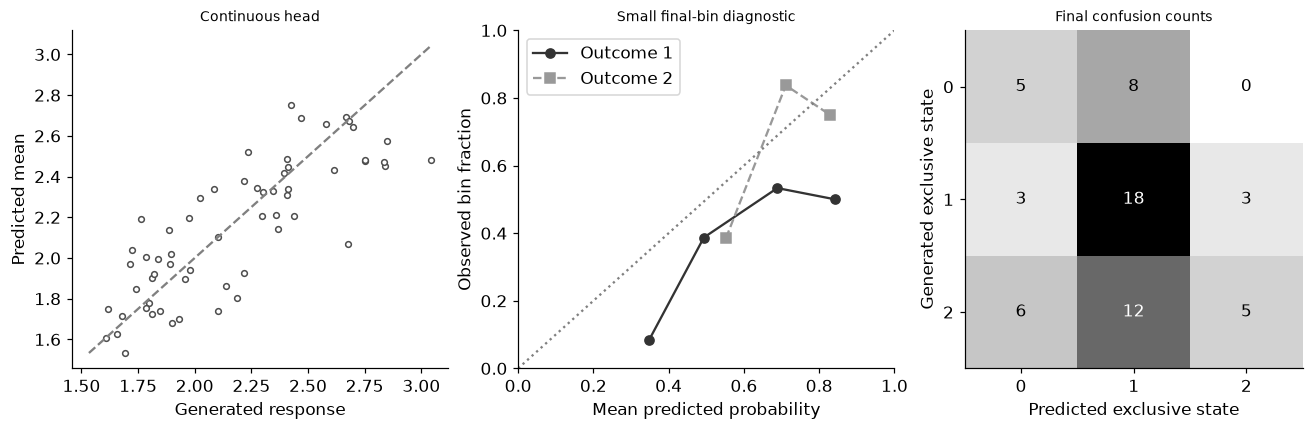

In [3]:
fig,axes=plt.subplots(1,3,figsize=(12,3.8));mean,var,p,classes=outputs
axes[0].scatter(response[final],mean,s=14,facecolors='white',edgecolors='.3');limits=[min(response[final].min(),mean.min()),max(response[final].max(),mean.max())];axes[0].plot(limits,limits,'--',color='.5');axes[0].set(xlabel='Generated response',ylabel='Predicted mean',title='Continuous head')
edges=np.linspace(0,1,6)
for j in range(2):
    points=[]
    for lo,hi in zip(edges[:-1],edges[1:]):
        mask=(p[:,j]>=lo)&(p[:,j]<(hi if hi<1 else 1.000001))
        if mask.any():points.append([p[mask,j].mean(),binary[final][mask,j].mean()])
    points=np.array(points);axes[1].plot(points[:,0],points[:,1],['o-','s--'][j],color=str(.2+j*.4),label=f'Outcome {j+1}')
axes[1].plot([0,1],[0,1],':',color='.5');axes[1].set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',ylabel='Observed bin fraction',title='Small final-bin diagnostic');axes[1].legend()
counts=confusion_matrix(state[final],classes.argmax(1),labels=range(3));axes[2].imshow(counts,cmap='Greys');axes[2].set(xlabel='Predicted exclusive state',ylabel='Generated exclusive state',title='Final confusion counts',xticks=range(3),yticks=range(3))
for i in range(3):
    for j in range(3):axes[2].text(j,i,str(counts[i,j]),ha='center',va='center',color='white' if counts[i,j]>counts.max()/2 else 'black')
plt.show();assert counts.sum()==60


In [4]:
summary={'example_id':'code_103','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['continuous and categorical inputs', 'shared feedforward torso', 'Gaussian and classification heads', 'output-shape and unknown-category contracts'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["continuous and categorical inputs", "shared feedforward torso", "Gaussian and classification heads", "output-shape and unknown-category contracts"], "elapsed_seconds": 1.079, "example_id": "code_103", "hardware": "Darwin arm64 CPU", "results": {"development": {"Gaussian_NLL": 0.09246967637009487, "MSE": 0.05262131293718684, "binary_Brier": 0.24706653436365447, "exclusive_accuracy": 0.4166666666666667, "exclusive_cross_entropy": 1.1128787942333527}, "final": {"Gaussian_NLL": -0.0035485595411644125, "MSE": 0.049824395150531525, "binary_Brier": 0.2081116059488231, "exclusive_accuracy": 0.4666666666666667, "exclusive_cross_entropy": 1.1538845291582753}, "head_shapes": {"binary_logits": [60, 2], "exclusive_logits": [60, 3], "mean": [60], "variance": [60]}, "parameter_count": 161, "split_buildings": [40, 10, 10], "training_losses": [[0, 5.818278663535724, 0.7380839854986394, 1.1323469553686571], [25, 1.335782083108304, 0.6416932581399486, 1.